# 34 — Computer Vision Fundamentals

## 1. Introduction to Computer Vision

### What is Computer Vision?

**Computer Vision (CV)** is a field of Artificial Intelligence that enables computers to **extract meaningful information from images and videos** and perform tasks such as classification, detection, recognition, localization, and segmentation.

> **Core idea:** Convert visual data into useful information, predictions, or decisions.



A computer does not see an image in the same way humans do. An image is represented numerically.

For an RGB image:

$$
I \in \mathbb{R}^{H \times W \times 3}
$$

where:

- $H$ = image height
- $W$ = image width
- $3$ = RGB channels

Conceptually:

```text
Image
  ↓
Pixels
  ↓
Numerical representation
  ↓
Visual patterns
  ↓
Objects / regions / concepts
```

---

## 2. Image Understanding

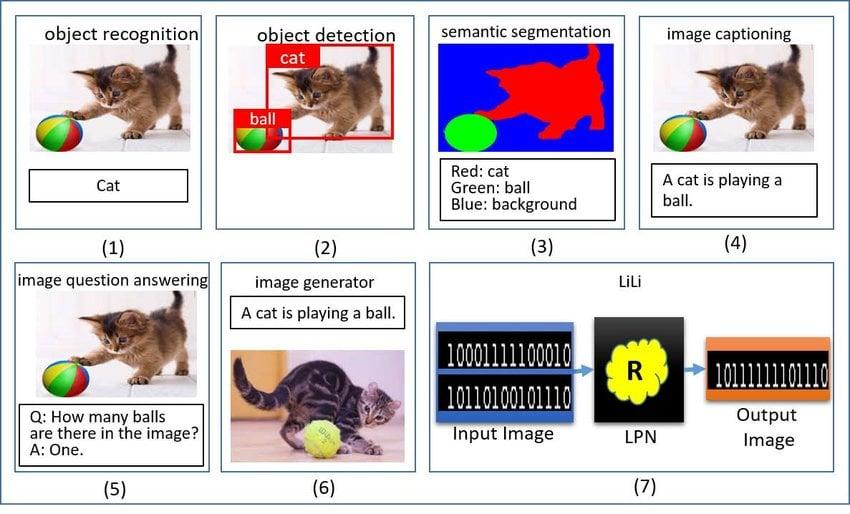

**Image understanding** refers to extracting meaningful semantic information from an image.

For example, a human looking at an image might understand:

> "A person is riding a bicycle on a road."

A computer vision system may need to identify:

- **Objects:** person, bicycle, road
- **Locations:** where each object appears
- **Relationships:** person → riding → bicycle
- **Regions:** which pixels belong to which objects/classes



---

# 3. Image Classification

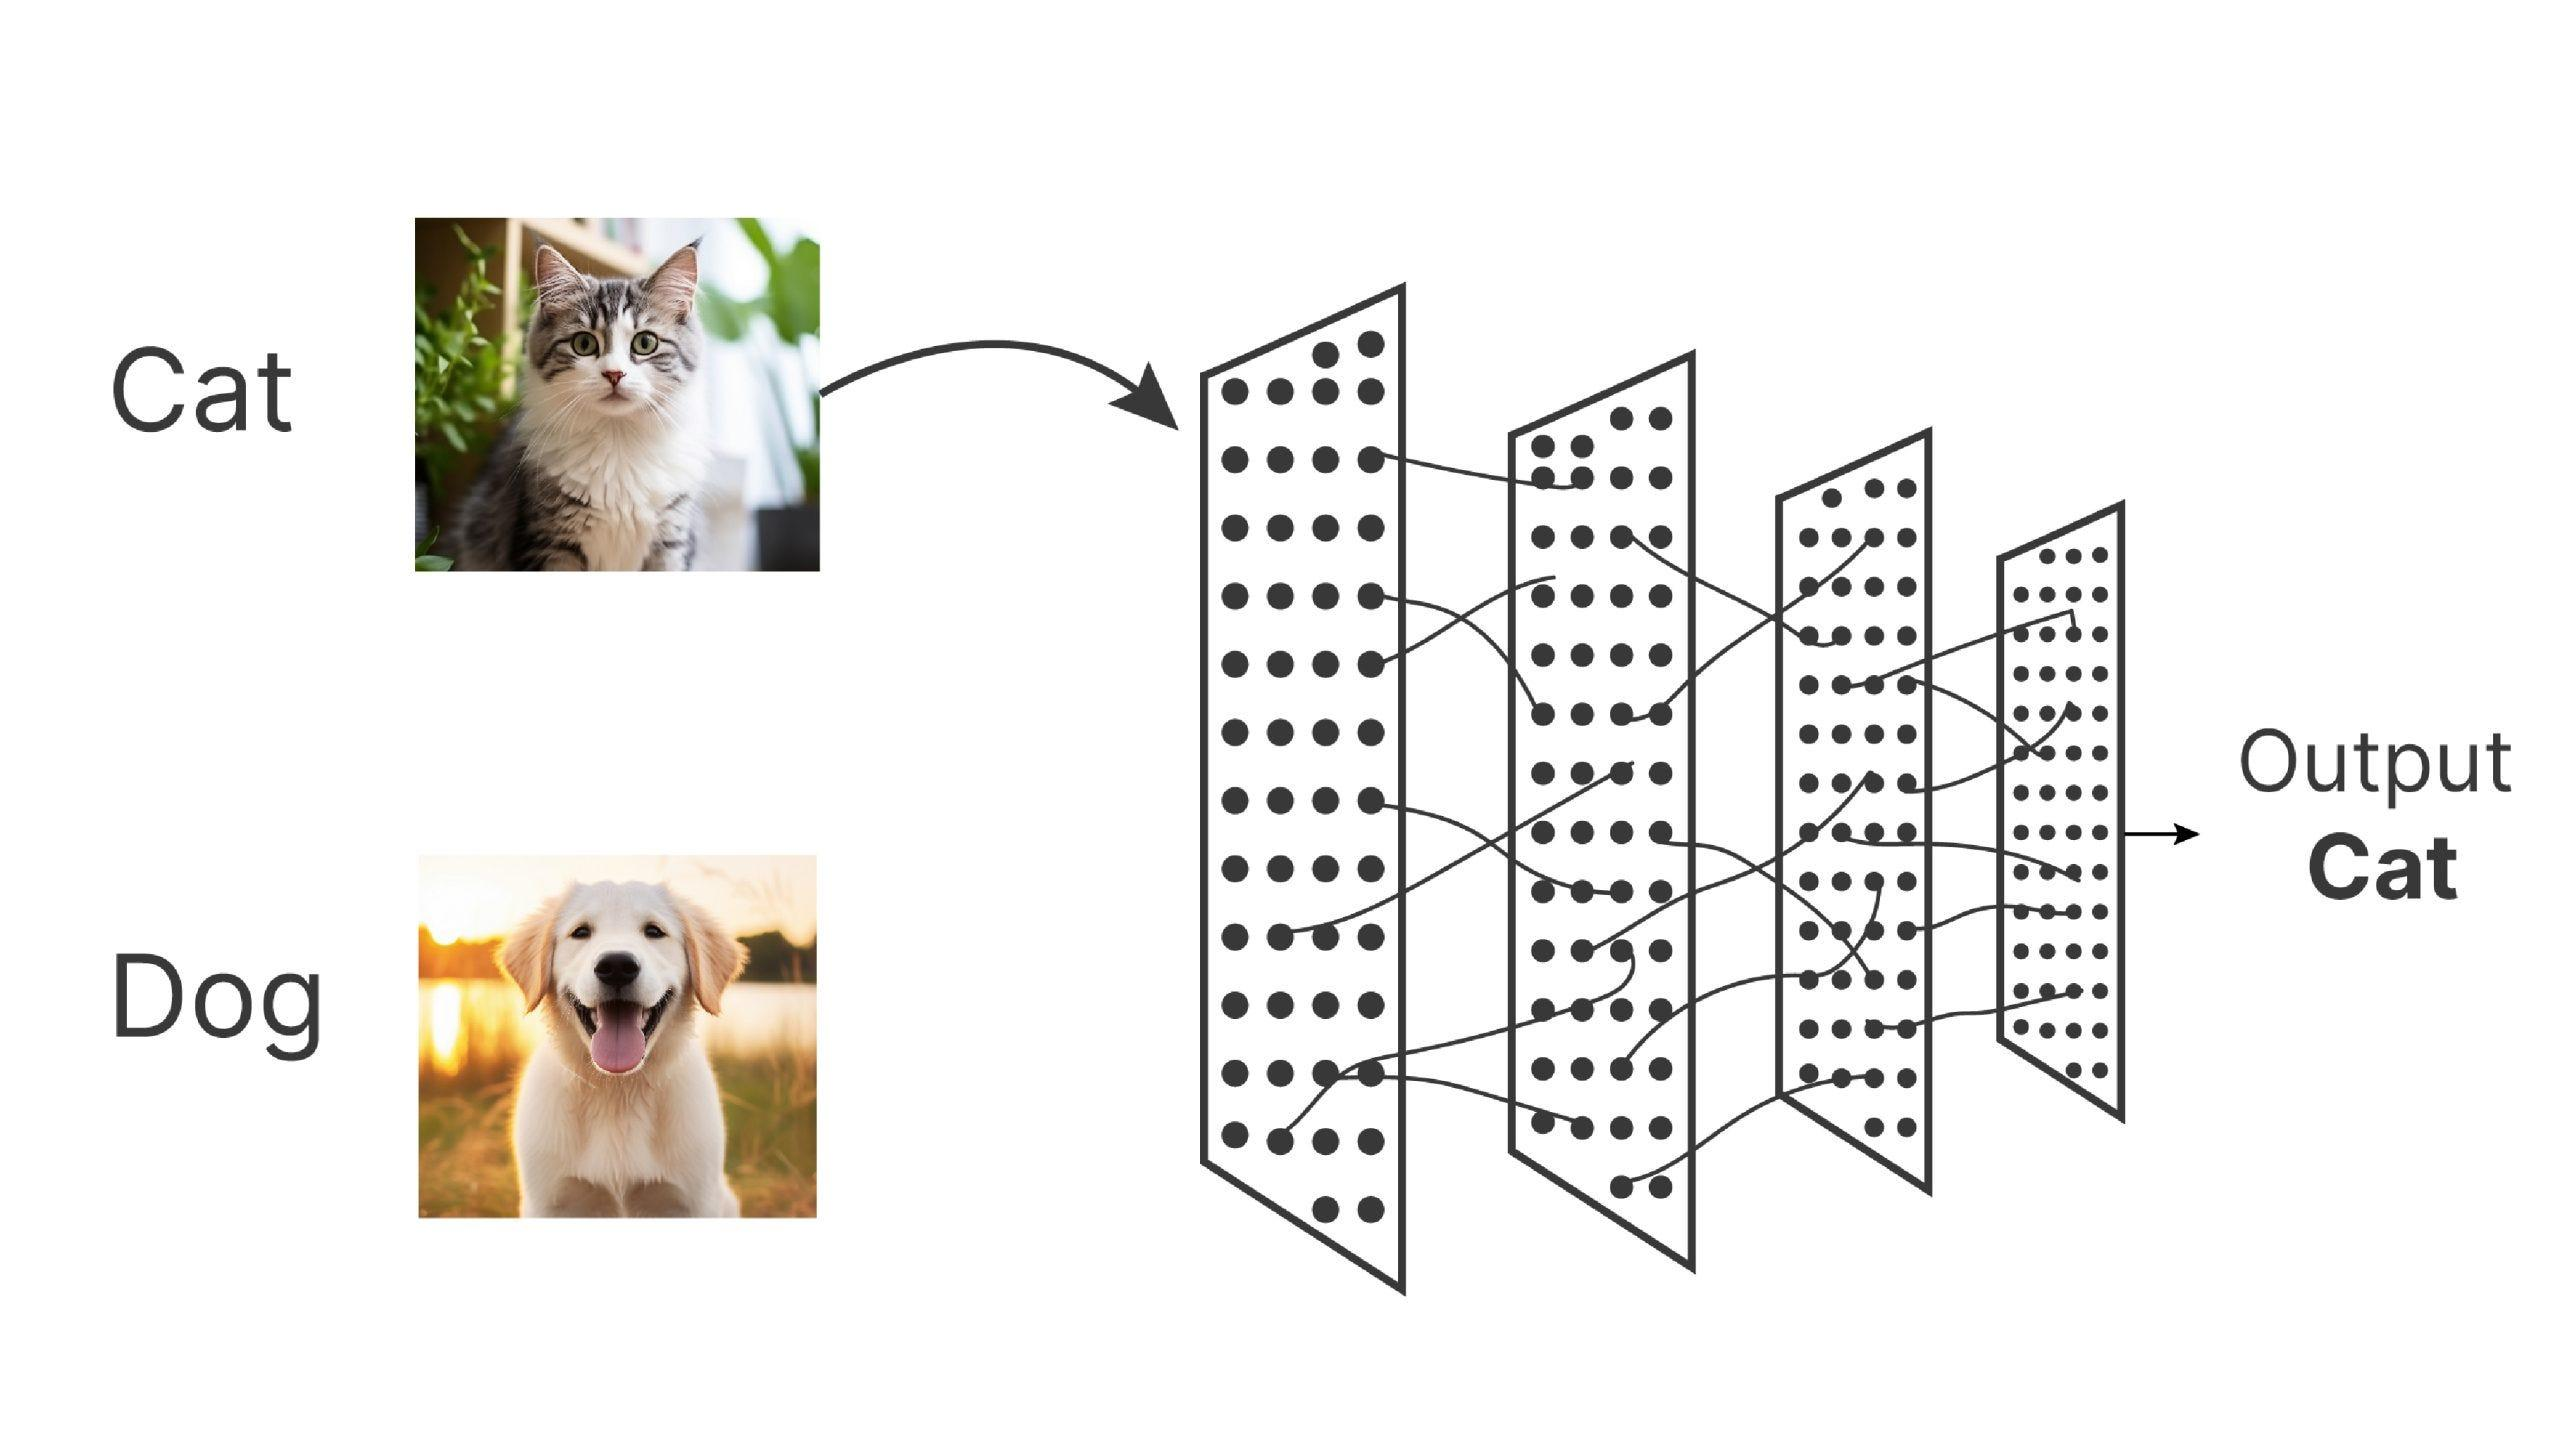

### Definition

**Image classification** assigns a class/category to an image.

### Main question

> **"What is this image?"**

Example:

```text
Input Image
     ↓
Classification Model
     ↓
     DOG
```

Suppose the possible classes are:

```text
Cat
Dog
Horse
```

The model might produce:

$$
P(cat)=0.05
$$

$$
P(dog)=0.92
$$

$$
P(horse)=0.03
$$

Therefore:

$$
\boxed{\text{Prediction} = Dog}
$$



### Key characteristic

Classification generally produces a label for the **whole image**.

```text
Image
  ↓
"What?"
  ↓
CAT
```

It does **not necessarily tell us where the cat is**.

### Example applications

- Cat vs dog classification
- Disease classification from medical images
- Product category classification
- Defect classification

---

# 4. Localization

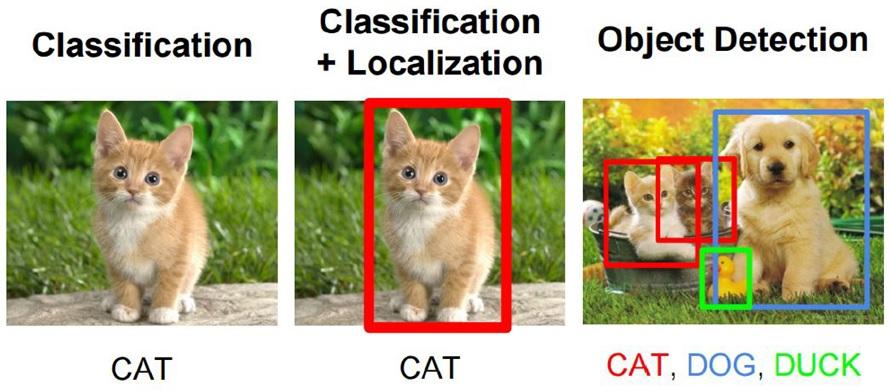

### Definition

**Object localization** determines **where an object is** in an image, usually using a bounding box.

### Main questions

> **"What is it?"**

and

> **"Where is it?"**

Example:

```text
Input image
     ↓
Localization
     ↓
Cat + Bounding Box
```



A bounding box can be represented as:

$$
(x_{min},y_{min},x_{max},y_{max})
$$

or using another convention:

$$
(x,y,w,h)
$$

where:

- $x,y$ → position
- $w$ → width
- $h$ → height

### Mental model

```text
Classification
→ WHAT?

Localization
→ WHAT + WHERE?
```

---

# 5. Object Detection

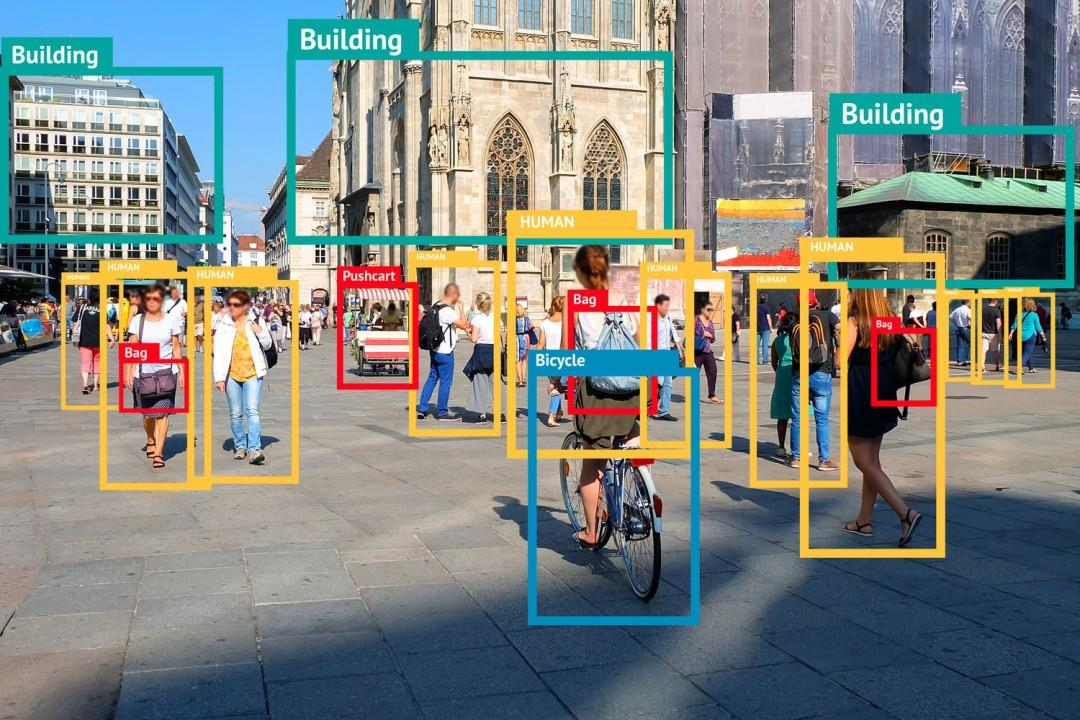

### Definition

**Object detection** identifies **multiple objects** and determines the location of each object.

### Main question

> **"What objects are present, and where are they?"**



For example:

```text
Image
  ↓
Object Detection
  ↓
Person → bounding box
Car    → bounding box
Dog    → bounding box
```

A detection can contain:

$$
(\text{class},\text{confidence},\text{bounding box})
$$

Example:

| Object | Confidence | Location |
|---|---:|---|
| Person | 0.97 | Bounding box |
| Car | 0.94 | Bounding box |
| Dog | 0.89 | Bounding box |

### Important relationship

$$
\boxed{\text{Object Detection} \approx \text{Classification + Localization}}
$$

The important conceptual distinction is:

```text
Classification
→ one/more image-level labels

Localization
→ object + location

Detection
→ multiple objects + locations
```

---

# 6. Segmentation

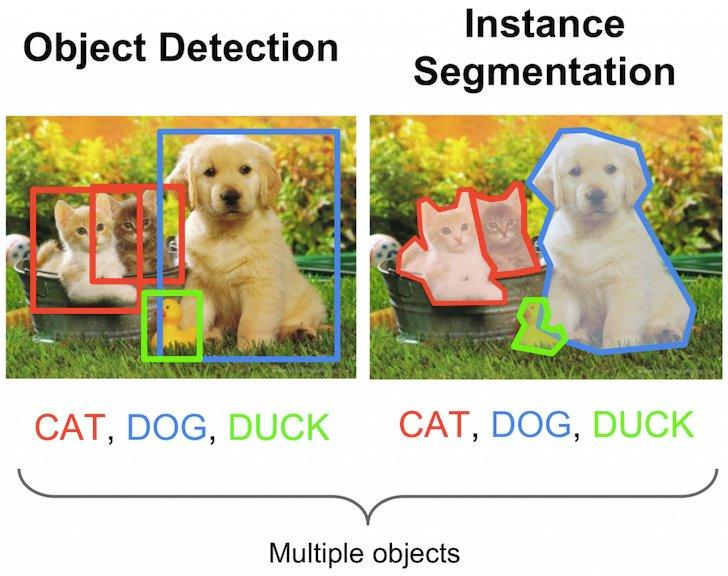

### Definition

**Image segmentation** assigns information at the **pixel level**.

Instead of asking:

> "Which rectangle contains the object?"

we ask:

> **"Which exact pixels belong to the object or region?"**



### Detection

```text
       ┌───────────────────┐
       │      Object       │
       │                   │
       └───────────────────┘
          Bounding Box
```

The box also contains background pixels.

### Segmentation

```text
       Exact object pixels
          ███████
        ███████████
         █████████
```

The model predicts a **mask** indicating which pixels belong to which region/object.

---

# 7. Semantic Segmentation

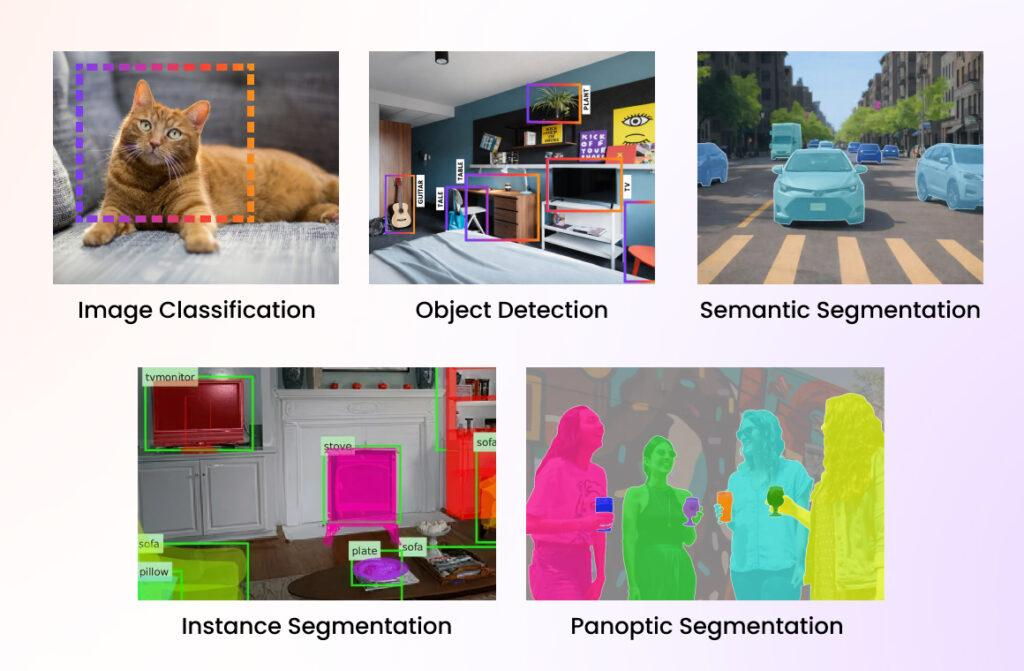

### Definition

**Semantic segmentation** assigns a class label to **every pixel**.

For example:

```text
Sky       → sky
Road      → road
Car       → car
Person    → person
```



If there are three cars:

```text
Car  Car  Car
```

all three belong to the same semantic class:

```text
CAR
```

The model does not necessarily distinguish **Car 1** from **Car 2**.

---

# 8. Instance Segmentation

**Instance segmentation** goes one step further.

It identifies:

1. The semantic class
2. The individual object instance

Example:

```text
Car 1 → instance 1
Car 2 → instance 2
Car 3 → instance 3
```



So:

```text
Semantic segmentation
→ "These pixels are CAR."

Instance segmentation
→ "These pixels are CAR 1,
   those pixels are CAR 2."
```

---

# 9. Panoptic Segmentation

**Panoptic segmentation** combines semantic and instance-level understanding.

Conceptually:

```text
Every pixel
    ↓
Semantic class
    +
Object instance when applicable
```

For example:

```text
Sky      → semantic region
Road     → semantic region
Car 1    → instance
Car 2    → instance
Person 1 → instance
```



---

# 10. Recognition

### Definition

**Recognition** is the ability of a computer vision system to identify meaningful visual entities or concepts.

Examples:

```text
Image
 ↓
Recognize:
 ├── Person
 ├── Bicycle
 ├── Road
 └── Traffic sign
```

Recognition can involve identifying:

- Objects
- People
- Places
- Text
- Visual concepts
- Other meaningful entities



### Simple mental model

> **Recognition → "What is it?"**

while:

> **Localization → "Where is it?"**

and:

> **Segmentation → "Which pixels belong to it?"**

---

# 11. Classification vs Localization vs Detection vs Segmentation

This is one of the **most important comparisons** in this module.



| Task | Main Question | Typical Output |
|---|---|---|
| **Classification** | What is in the image? | Class label |
| **Recognition** | What entities/concepts are present? | Recognized entities |
| **Localization** | Where is the object? | Bounding box |
| **Object Detection** | What + where for objects? | Classes + bounding boxes |
| **Semantic Segmentation** | What class does each pixel belong to? | Pixel-level class map |
| **Instance Segmentation** | Which pixels belong to each object instance? | Individual object masks |
| **Panoptic Segmentation** | What class + which instance for each pixel? | Semantic + instance masks |

---

# 12. One Visual Mental Model

```text
                         IMAGE
                           │
                           ▼
                ┌──────────────────┐
                │ Computer Vision  │
                └──────────────────┘
                           │
          ┌────────────────┼─────────────────┐
          │                │                 │
          ▼                ▼                 ▼
     WHAT IS IT?       WHERE IS IT?     WHICH PIXELS?
          │                │                 │
          ▼                ▼                 ▼
   Classification     Localization      Segmentation
          │
          │
          └──────────────┐
                         ▼
                 Object Detection
                  WHAT + WHERE
```

### Remember:

> **Classification → WHAT**

> **Localization → WHERE**

> **Detection → WHAT + WHERE**

> **Segmentation → WHICH PIXELS**

---

# 13. Example: Autonomous Driving 🚗

Consider an autonomous-driving camera.



The system may need to identify:

```text
Car
Pedestrian
Bicycle
Traffic light
Road
Sidewalk
Traffic sign
```

Different CV tasks can be applied:

### Classification

```text
Image → Road scene
```

### Recognition

```text
Recognize:
Car
Pedestrian
Traffic light
Bicycle
```

### Localization

```text
Pedestrian → Bounding box
```

### Object Detection

```text
Car        → Box
Pedestrian → Box
Bicycle    → Box
```

### Segmentation

```text
Road       → Road pixels
Sidewalk   → Sidewalk pixels
Car        → Car pixels
Pedestrian → Pedestrian pixels
```

The **same image** can therefore support different prediction tasks depending on what the application needs.

---

# 14. Image Understanding as a Hierarchy

A useful conceptual hierarchy is:

```text
Pixels
  ↓
Edges
  ↓
Textures
  ↓
Shapes
  ↓
Parts
  ↓
Objects
  ↓
Scene
  ↓
Relationships / Understanding
```

For example:

```text
Pixels
  ↓
Edges
  ↓
Circular shape
  ↓
Wheel
  ↓
Bicycle
  ↓
Person riding bicycle
  ↓
Road scene
```

This hierarchy will become especially important when we study **CNNs and visual feature extraction**.

---

# 15. Real-World Applications

| Application | Typical CV Tasks |
|---|---|
| Medical imaging | Classification, detection, segmentation |
| Autonomous driving | Detection, segmentation, localization |
| Manufacturing inspection | Classification, detection, segmentation |
| OCR | Recognition |
| Retail | Detection, recognition |
| Satellite imagery | Classification, segmentation |
| Robotics | Detection, localization, segmentation |
| Sports analytics | Detection, tracking, recognition |
| Agriculture | Classification, detection, segmentation |

---

# 16. Must Know / Good to Know / Advanced

## 🔴 Must Know

- Definition of Computer Vision
- Image representation
- Image understanding
- Image classification
- Object localization
- Object detection
- Segmentation
- Recognition
- Bounding box
- Pixel mask
- Classification vs detection
- Detection vs segmentation
- Semantic vs instance segmentation

## 🟡 Good to Know

- Panoptic segmentation
- Confidence scores
- Bounding-box representations
- Real-world applications
- Why different tasks require different outputs

## 🟢 Optional / Advanced

- Classical computer vision
- SIFT
- HOG
- Traditional feature extraction
- Vision Transformers

These will become relevant at the appropriate points later in the CV progression.

---

# 17. Interview / GATE Points

### Q1. What is image classification?

> Assigning one or more class labels to an image based on its visual content.

### Q2. What is object localization?

> Predicting an object's class and spatial location, commonly using a bounding box.

### Q3. What is object detection?

> Identifying multiple object instances and predicting their classes and bounding boxes.

### Q4. Detection vs segmentation?

> Detection typically gives **bounding boxes**, while segmentation gives **pixel-level masks**.

### Q5. Semantic vs instance segmentation?

> Semantic segmentation assigns a class to each pixel; instance segmentation additionally distinguishes different objects belonging to the same class.

### Q6. What is the simplest mental model?

$$
\boxed{\text{Classification = WHAT}}
$$

$$
\boxed{\text{Localization = WHERE}}
$$

$$
\boxed{\text{Detection = WHAT + WHERE}}
$$

$$
\boxed{\text{Segmentation = WHICH PIXELS}}
$$

---

# 18. Key Takeaways

> **1. Computer Vision** deals with extracting meaningful information from images and videos.

> **2. Classification** predicts the class/category.

> **3. Localization** predicts where an object is.

> **4. Object detection** combines object identification with localization, typically using bounding boxes.

> **5. Segmentation** works at the pixel level.

> **6. Semantic segmentation** identifies pixel classes.

> **7. Instance segmentation** distinguishes individual objects.

> **8. The task determines the required output, and the required output helps determine the appropriate model.**

### Core revision chain

```text
IMAGE
  ↓
Classification → WHAT?
  ↓
Localization → WHERE?
  ↓
Detection → WHAT + WHERE?
  ↓
Segmentation → WHICH PIXELS?
```